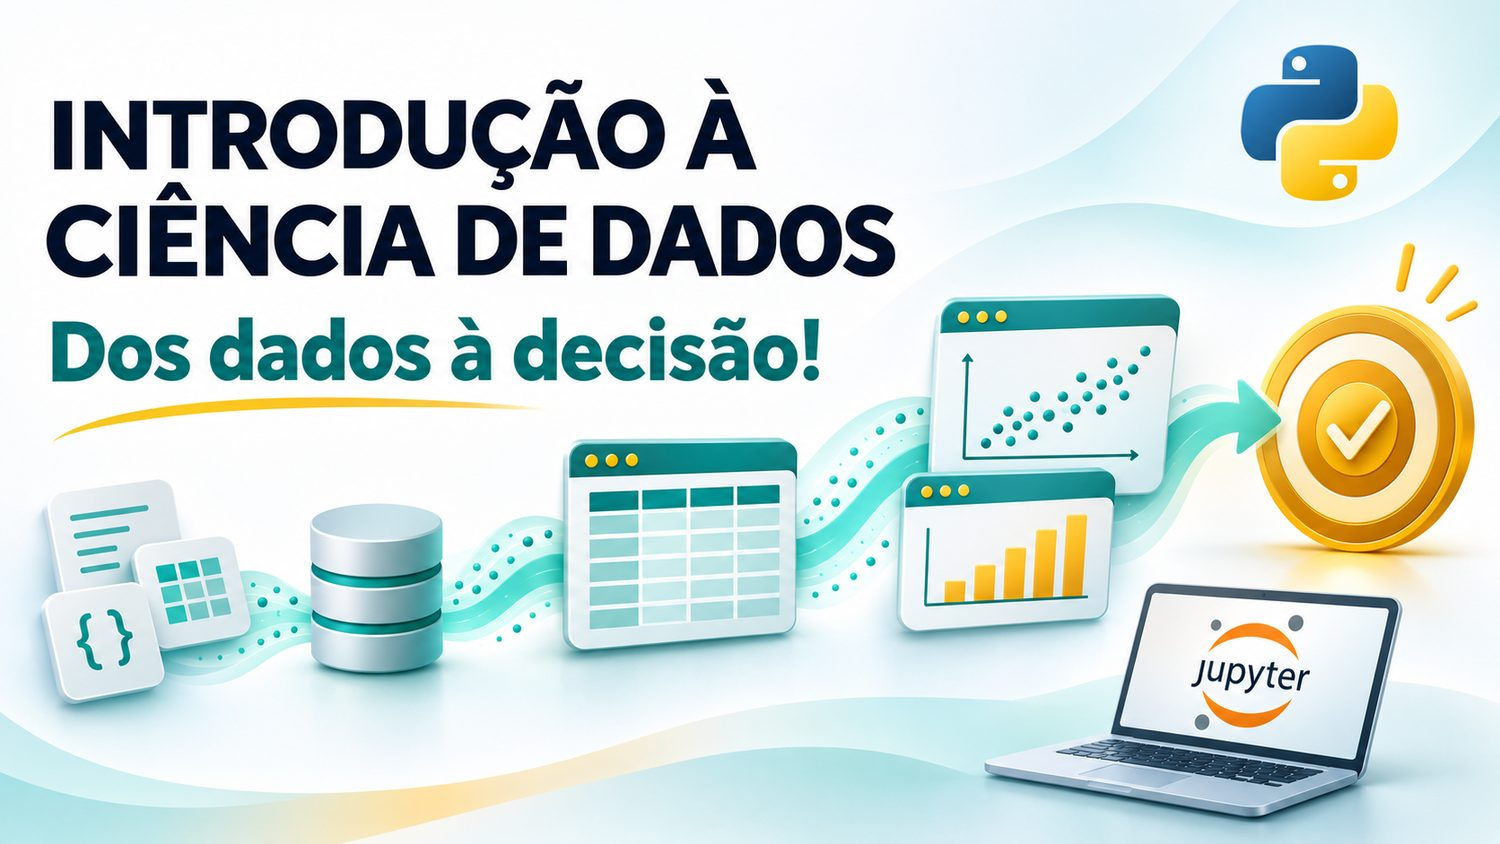

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_1_do_problema_a_decisao/03_Previsao_nao_e_Decisao.ipynb)

# Capítulo 3 – Uma boa previsão não garante uma boa decisão

Um modelo que acerta 93% das vezes parece bom. Neste capítulo construímos um modelo assim e descobrimos que, usado da forma mais óbvia, quase não ajuda ninguém. Depois vemos como se avalia uma previsão pelo que ela permite decidir, e como se define o sucesso de um projeto antes de o começar.

> **Objetivos:** comparar um modelo com uma linha de base; ler uma matriz de confusão; calcular exatidão, sensibilidade e precisão; perceber porque a exatidão engana quando o caso que interessa é raro; escolher um limiar de decisão a partir dos custos de cada erro; definir resultado, linha de base, restrições e critérios de sucesso.

**Pré-requisitos:** capítulos 1 e 2. As células usam o scikit-learn; se quiseres perceber o código em detalhe, vê o tutorial [Introdução ao Python](../../../Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python) (nível 2, módulos 3 e 4).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_consultas(n=10_000, semente=42):
    """Gera marcações de consultas de uma clínica fictícia (dados sintéticos)."""
    rng = np.random.default_rng(semente)
    antecedencia = rng.gamma(2.0, 9.0, n).round().clip(0, 90).astype(int)
    idade = rng.integers(18, 90, n)
    faltas_anteriores = rng.poisson(0.4, n)
    dia = rng.choice(["seg", "ter", "qua", "qui", "sex"], n)
    # A clínica envia mais lembretes por SMS a quem já faltou antes
    lembrete = rng.random(n) < 0.05 + 0.70 * (faltas_anteriores >= 1)
    z = (-3.7 + 0.05 * antecedencia + 1.0 * faltas_anteriores
         - 0.012 * (idade - 18) - 0.6 * lembrete + 0.3 * (dia == "seg"))
    faltou = rng.random(n) < 1 / (1 + np.exp(-z))
    return pd.DataFrame({"antecedencia_dias": antecedencia, "idade": idade,
                         "faltas_anteriores": faltas_anteriores, "dia_semana": dia,
                         "lembrete": lembrete, "faltou": faltou})


consultas = gerar_consultas()
consultas.head()

,antecedencia_dias,idade,faltas_anteriores,dia_semana,lembrete,faltou
0,19,55,2,qua,True,False
1,26,42,2,sex,True,False
2,17,48,0,ter,False,False
3,15,34,1,ter,False,False
4,28,43,0,sex,False,False


## Um modelo com 93% de exatidão

Vamos prever as faltas com uma regressão logística. Guardamos 30% das marcações para teste: o modelo não as vê durante o treino, e é nelas que medimos o desempenho.

In [3]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

X = consultas[["antecedencia_dias", "idade", "faltas_anteriores"]].assign(
    segunda=(consultas["dia_semana"] == "seg").astype(int), lembrete=consultas["lembrete"].astype(int))
y = consultas["faltou"]
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.3, random_state=0, stratify=y)

modelo = LogisticRegression(max_iter=2000).fit(X_treino, y_treino)
probabilidade = modelo.predict_proba(X_teste)[:, 1]   # probabilidade de falta de cada marcação
previsao = probabilidade >= 0.5                        # regra habitual: prever «falta» acima de 50%

exatidao = (previsao == y_teste).mean()
print(f"Marcações de teste: {len(y_teste)}")
print(f"Exatidão do modelo: {exatidao:.1%}")

Marcações de teste: 3000
Exatidão do modelo: 93.0%


A **exatidão** (*accuracy*) é a proporção de previsões certas. O modelo acerta em cerca de 93 de cada 100 marcações.

A clínica decide então: **telefonar apenas aos pacientes que o modelo prevê que vão faltar.** Parece uma boa decisão. Vamos verificar.

## Comparar com uma linha de base

Um número só tem significado quando comparado com outro. A comparação mais simples é com um «modelo» que não usa dados nenhuns e responde sempre a mesma coisa: **ninguém falta**.

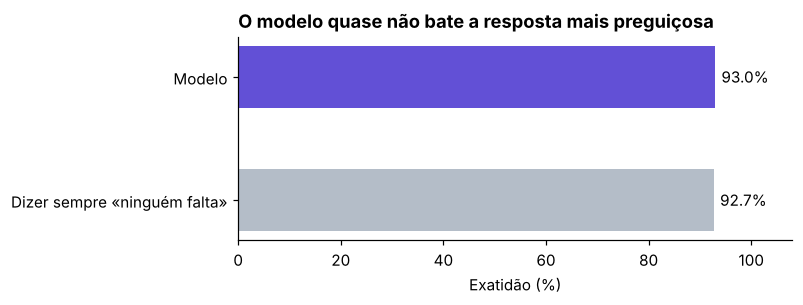

In [4]:
exatidao_base = (~y_teste).mean()   # acerta sempre que o paciente comparece

fig, ax = plt.subplots(figsize=(6.5, 2.4))
barras = ax.barh(["Dizer sempre «ninguém falta»", "Modelo"], [exatidao_base * 100, exatidao * 100],
                 color=[CINZA, VIOLETA], height=0.5)
ax.bar_label(barras, fmt="%.1f%%", padding=4)
ax.set_xlim(0, 108)
ax.set_xlabel("Exatidão (%)")
ax.set_title("O modelo quase não bate a resposta mais preguiçosa")
plt.show()

A resposta preguiçosa tem quase a mesma exatidão. A explicação é simples: como só cerca de 7% das marcações acabam em falta, quem disser sempre «vai comparecer» acerta 93% das vezes, e não identifica uma única falta.

> **Quando o caso que interessa é raro, a exatidão é dominada pelos casos que não interessam.**

## A matriz de confusão

Para perceber o que o modelo faz, é preciso separar os acertos e os erros em quatro grupos.

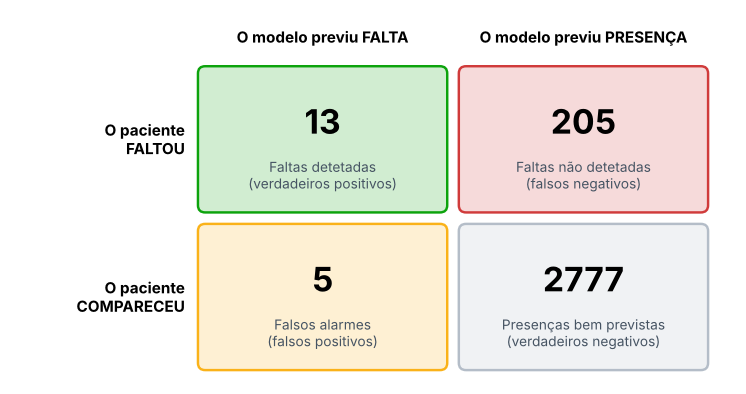

In [5]:
vp = int((previsao & y_teste).sum())      # previu falta e faltou
fn = int((~previsao & y_teste).sum())     # previu que comparecia e faltou
fp = int((previsao & ~y_teste).sum())     # previu falta e compareceu
vn = int((~previsao & ~y_teste).sum())    # previu que comparecia e compareceu

fig, ax = tela(10, 5.2, (8.5, 4.4))
celulas = [(2.6, 2.4, vp, "Faltas detetadas\n(verdadeiros positivos)", BOM),
           (6.2, 2.4, fn, "Faltas não detetadas\n(falsos negativos)", MAU),
           (2.6, 0.2, fp, "Falsos alarmes\n(falsos positivos)", AVISO),
           (6.2, 0.2, vn, "Presenças bem previstas\n(verdadeiros negativos)", CINZA)]
for x, y0, valor, rotulo, cor in celulas:
    caixa(ax, x, y0, 3.4, 2.0, "", cor)
    ax.text(x + 1.7, y0 + 1.25, str(valor), ha="center", va="center", fontsize=22, fontweight="bold")
    ax.text(x + 1.7, y0 + 0.5, rotulo, ha="center", va="center", fontsize=9, color="#465463")
ax.text(4.3, 4.75, "O modelo previu FALTA", ha="center", fontweight="bold")
ax.text(7.9, 4.75, "O modelo previu PRESENÇA", ha="center", fontweight="bold")
ax.text(2.4, 3.4, "O paciente\nFALTOU", ha="right", va="center", fontweight="bold")
ax.text(2.4, 1.2, "O paciente\nCOMPARECEU", ha="right", va="center", fontweight="bold")
plt.show()

A célula vermelha é o problema: são os pacientes que faltaram e a quem ninguém telefonou. A figura seguinte mostra as mesmas marcações de teste, uma por ponto.

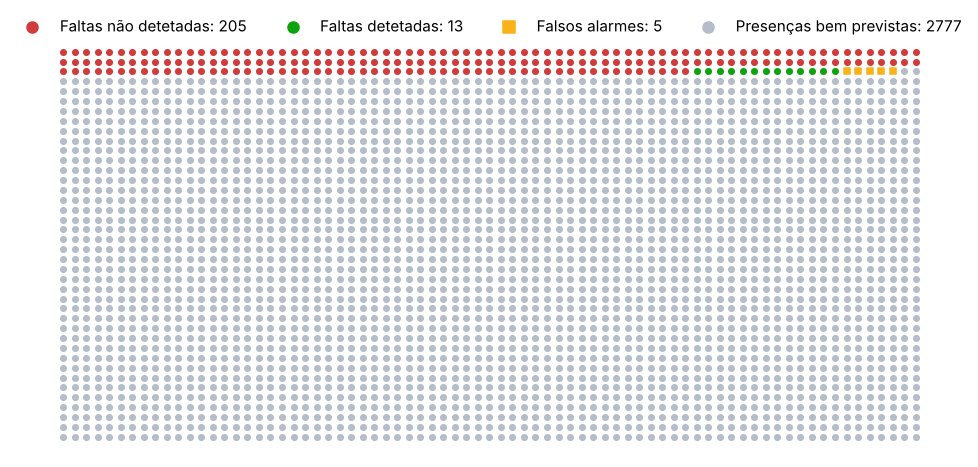

Dos 218 pacientes que faltaram, o modelo sinalizou 13.
Ficaram 205 sem chamada: 94% de quem faltou.


In [6]:
grupos = [("Faltas não detetadas", fn, MAU, "o"), ("Faltas detetadas", vp, BOM, "o"),
          ("Falsos alarmes", fp, AVISO, "s"), ("Presenças bem previstas", vn, CINZA, "o")]
colunas = 75
posicao = np.arange(len(y_teste))
fig, ax = plt.subplots(figsize=(11, 5))
inicio = 0
for nome, quantos, cor, marcador in grupos:
    indices = posicao[inicio:inicio + quantos]
    ax.scatter(indices % colunas, -(indices // colunas), s=13, color=cor, marker=marcador, label=f"{nome}: {quantos}")
    inicio += quantos
ax.axis("off")
ax.legend(ncol=4, frameon=False, loc="upper center", bbox_to_anchor=(0.5, 1.07), markerscale=2)
plt.show()

print(f"Dos {vp + fn} pacientes que faltaram, o modelo sinalizou {vp}.")
print(f"Ficaram {fn} sem chamada: {fn / (vp + fn):.0%} de quem faltou.")

A decisão «telefonar a quem o modelo prevê que falta» deixa de fora quase todos os pacientes que faltam. Um modelo com 93% de exatidão produziu uma decisão quase inútil.

### Três medidas, três perguntas

| Medida | Pergunta | Fórmula |
| --- | --- | --- |
| **Exatidão** (*accuracy*) | Em quantas marcações acertei? | (VP + VN) / total |
| **Sensibilidade** (*recall*) | Das faltas que houve, quantas apanhei? | VP / (VP + FN) |
| **Precisão** (*precision*) | Das faltas que anunciei, quantas se confirmaram? | VP / (VP + FP) |

In [7]:
print(f"Exatidão:      {(vp + vn) / len(y_teste):.1%}")
print(f"Sensibilidade: {vp / (vp + fn):.1%}")
print(f"Precisão:      {vp / (vp + fp):.1%}")

Exatidão:      93.0%
Sensibilidade: 6.0%
Precisão:      72.2%


A sensibilidade é a medida que denuncia o problema. Para esta decisão, é ela que importa: uma falta que escapa custa uma vaga.

## O limiar é uma decisão, não um pormenor técnico

O modelo não devolve «falta» ou «presença». Devolve uma **probabilidade**. Somos nós que escolhemos a partir de que valor telefonamos, e os 50% que usámos são apenas um hábito.

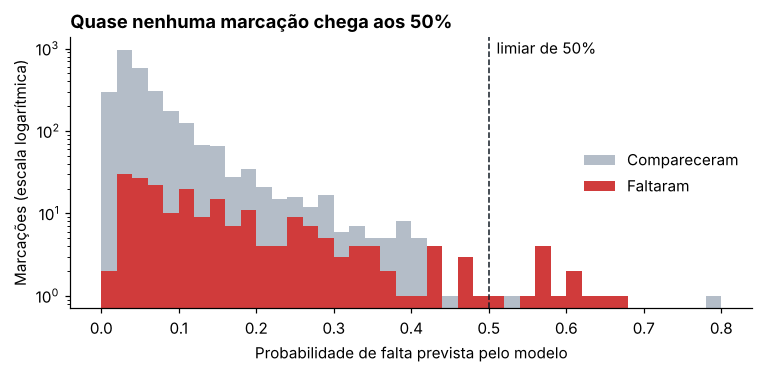

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.2))
intervalos = np.linspace(0, 0.8, 41)
ax.hist(probabilidade[~y_teste.values], bins=intervalos, color=CINZA, label="Compareceram")
ax.hist(probabilidade[y_teste.values], bins=intervalos, color=MAU, label="Faltaram")
ax.axvline(0.5, color=TINTA, ls="--", lw=1)
ax.text(0.51, ax.get_ylim()[1] * 0.85, "limiar de 50%")
ax.set_yscale("log")
ax.set_xlabel("Probabilidade de falta prevista pelo modelo")
ax.set_ylabel("Marcações (escala logarítmica)")
ax.set_title("Quase nenhuma marcação chega aos 50%")
ax.legend(frameon=False)
plt.show()

Faltar é raro, por isso o modelo raramente atribui mais de 50% de probabilidade a alguém. Mas uma marcação com 20% de probabilidade de falta tem quase três vezes o risco médio. Vale a pena telefonar.

A tabela seguinte mostra o que acontece quando baixamos o limiar.

In [9]:
def avaliar(limiar):
    chamada = probabilidade >= limiar
    vp_ = int((chamada & y_teste).sum())
    return {"limiar": limiar, "chamadas": int(chamada.sum()), "faltas alcançadas": vp_,
            "sensibilidade": vp_ / y_teste.sum(), "precisão": vp_ / max(chamada.sum(), 1),
            "exatidão": (chamada == y_teste).mean()}


limiares = [0.50, 0.30, 0.20, 0.15, 0.10, 0.08, 0.05, 0.03]
tabela = pd.DataFrame([avaliar(t) for t in limiares]).set_index("limiar")
tabela.assign(**{"sensibilidade": tabela["sensibilidade"].map("{:.0%}".format), "precisão": tabela["precisão"].map("{:.0%}".format),
                 "exatidão": tabela["exatidão"].map("{:.1%}".format)})

,chamadas,faltas alcançadas,sensibilidade,precisão,exatidão
limiar,,,,,
0.50,18,13,6%,72%,93.0%
0.30,80,36,17%,45%,92.5%
0.20,190,65,30%,34%,90.7%
0.15,309,90,41%,29%,88.4%
0.10,572,127,58%,22%,82.1%
0.08,757,137,63%,18%,76.6%
0.05,1352,173,79%,13%,59.2%
0.03,2176,199,91%,9%,33.5%


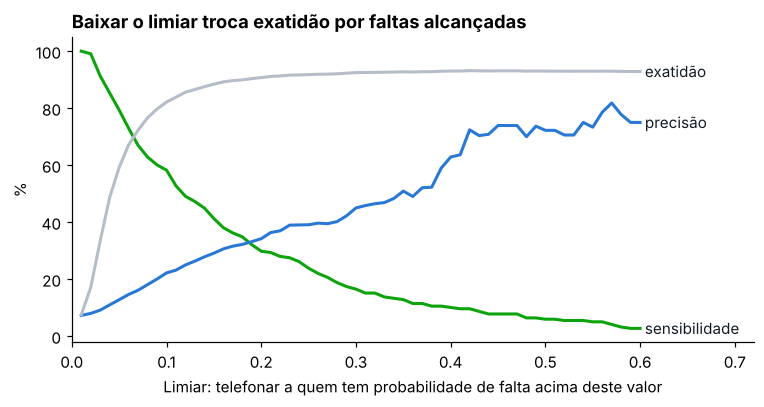

In [10]:
todos = np.linspace(0.01, 0.6, 60)
curvas = pd.DataFrame([avaliar(t) for t in todos])

fig, ax = plt.subplots(figsize=(8, 3.6))
for coluna, cor in [("sensibilidade", BOM), ("precisão", AZUL), ("exatidão", CINZA)]:
    ax.plot(curvas["limiar"], curvas[coluna] * 100, color=cor, lw=2)
    ax.text(0.605, curvas[coluna].iloc[-1] * 100, coluna, color=TINTA, va="center")
ax.set_xlim(0, 0.72)
ax.set_xlabel("Limiar: telefonar a quem tem probabilidade de falta acima deste valor")
ax.set_ylabel("%")
ax.set_title("Baixar o limiar troca exatidão por faltas alcançadas")
plt.show()

Ao baixar o limiar:

- a **sensibilidade** sobe: alcançamos mais pacientes que iam faltar;
- a **precisão** desce: fazemos mais chamadas a quem ia comparecer de qualquer forma;
- a **exatidão** desce, e isso não tem importância nenhuma para a clínica.

Não existe um limiar «correto» em abstrato. O melhor depende do que custa cada tipo de erro.

## Pôr custos nos erros

Para escolher o limiar precisamos de três números. Vamos assumir os seguintes (são **pressupostos**, que uma clínica real teria de medir):

| Pressuposto | Valor |
| --- | --- |
| Custo de uma vaga perdida por falta | 60 € |
| Custo de uma chamada de confirmação | 2 € |
| Faltas evitadas por uma chamada | metade |

Com estes valores, cada limiar tem um custo total: as chamadas feitas mais as vagas que se perdem na mesma.

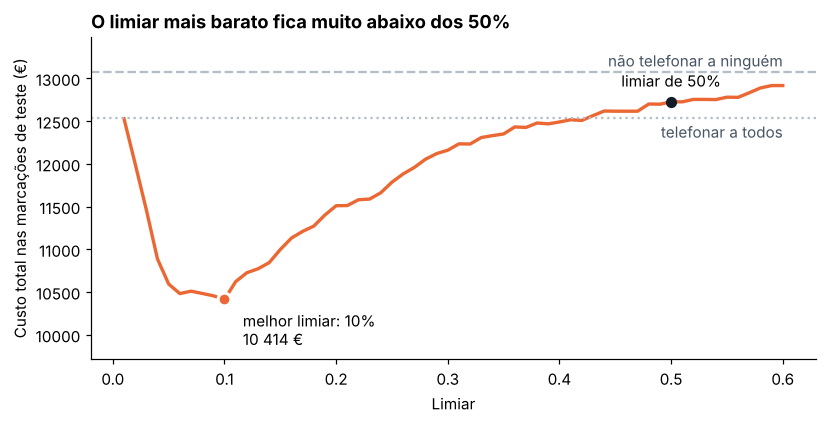

Melhor limiar: 10%  →  572 chamadas, sensibilidade 58%, exatidão 82.1%
Poupança face a não telefonar: 2 666 € (20%)


In [11]:
CUSTO_FALTA, CUSTO_CHAMADA, EFICACIA = 60, 2, 0.5


def custo_total(limiar):
    chamada = probabilidade >= limiar
    alcancadas = (chamada & y_teste).sum()
    nao_alcancadas = (~chamada & y_teste).sum()
    vagas_perdidas = nao_alcancadas + alcancadas * (1 - EFICACIA)
    return chamada.sum() * CUSTO_CHAMADA + vagas_perdidas * CUSTO_FALTA


custos = np.array([custo_total(t) for t in todos])
melhor = todos[custos.argmin()]
sem_chamadas = y_teste.sum() * CUSTO_FALTA
a_todos = len(y_teste) * CUSTO_CHAMADA + y_teste.sum() * (1 - EFICACIA) * CUSTO_FALTA

fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.plot(todos, custos, color=LARANJA, lw=2.2)
ax.axhline(sem_chamadas, color=CINZA, ls="--")
ax.text(0.6, sem_chamadas + 60, "não telefonar a ninguém", ha="right", color="#465463")
ax.axhline(a_todos, color=CINZA, ls=":")
ax.text(0.6, a_todos - 60, "telefonar a todos", ha="right", va="top", color="#465463")
ax.scatter([melhor], [custos.min()], color=LARANJA, s=70, zorder=3, edgecolor="white", linewidth=2)
ax.annotate(f"melhor limiar: {melhor:.0%}\n{custos.min():,.0f} €".replace(",", " "), (melhor, custos.min()),
            textcoords="offset points", xytext=(12, -8), va="top")
ax.scatter([0.5], [custo_total(0.5)], color=TINTA, s=40, zorder=3)
ax.annotate("limiar de 50%", (0.5, custo_total(0.5)), textcoords="offset points", xytext=(0, 10), ha="center")
ax.set_ylim(custos.min() - 700, sem_chamadas + 400)
ax.set_xlabel("Limiar")
ax.set_ylabel("Custo total nas marcações de teste (€)")
ax.set_title("O limiar mais barato fica muito abaixo dos 50%")
plt.show()

resumo = avaliar(melhor)
print(f"Melhor limiar: {melhor:.0%}  →  {resumo['chamadas']} chamadas, "
      f"sensibilidade {resumo['sensibilidade']:.0%}, exatidão {resumo['exatidão']:.1%}")
print(f"Poupança face a não telefonar: {sem_chamadas - custos.min():,.0f} € "
      f"({(sem_chamadas - custos.min()) / sem_chamadas:.0%})".replace(",", " "))

O limiar que minimiza o custo fica perto dos 10%, e a sua exatidão é **mais baixa** do que a da resposta preguiçosa. Mesmo assim é a melhor decisão das três: custa menos do que não telefonar a ninguém e menos do que telefonar a todos.

Há uma forma rápida de encontrar o ponto de equilíbrio sem modelo nenhum. Uma chamada compensa quando o que se espera recuperar é maior do que o que custa:

$$p \times 0{,}5 \times 60\ € > 2\ € \quad\Longrightarrow\quad p > 6{,}7\%$$

Ou seja, com estes custos vale a pena telefonar a qualquer paciente com mais de cerca de 7% de probabilidade de faltar. O limiar de 50% só faria sentido se cada chamada custasse 15 €.

> **O mesmo modelo, com as mesmas previsões, dá uma decisão má ou uma decisão boa conforme a forma como é usado.** A qualidade de um projeto mede-se na decisão, não na pontuação do modelo.

### E quando há um limite de recursos?

O limiar ótimo pede várias centenas de chamadas. Se a receção só conseguir fazer 150, a decisão muda outra vez: telefona-se às 150 marcações de maior risco.

In [12]:
capacidade = 150
ordem = np.argsort(-probabilidade)[:capacidade]
alcancadas = int(y_teste.values[ordem].sum())
print(f"Com {capacidade} chamadas às marcações de maior risco alcançam-se {alcancadas} faltas "
      f"({alcancadas / y_teste.sum():.0%} do total).")
print(f"Ao acaso, as mesmas chamadas alcançariam cerca de {capacidade * y_teste.mean():.0f}.")

Com 150 chamadas às marcações de maior risco alcançam-se 58 faltas (27% do total).
Ao acaso, as mesmas chamadas alcançariam cerca de 11.


## Definir o sucesso antes de começar

O que acabámos de fazer no fim devia ter sido feito no princípio. Antes de treinar um modelo, um projeto precisa de quatro definições.

| Elemento | Pergunta | No caso da clínica |
| --- | --- | --- |
| **Resultado** | Que mudança real queremos? | Menos vagas vazias, sem piorar o acesso às consultas. |
| **Evidência e linha de base** | Com que comparamos? | A prática atual (lembretes por SMS a quem já faltou) e a opção de não fazer nada. |
| **Restrições e erros** | Que limites temos e quanto custa cada erro? | 150 chamadas por dia; uma vaga perdida custa 60 €, uma chamada 2 €; ninguém deve ser prejudicado por ter faltado no passado. |
| **Critérios de sucesso** | Como saberemos que resultou? | Na análise: alcançar mais faltas do que a regra atual, com as mesmas chamadas. No mundo real: a taxa de faltas desce pelo menos dois pontos percentuais em três meses. |

Repara que há **dois** critérios de sucesso. O critério analítico mede-se nos dados de teste. O critério real só se mede depois de pôr a decisão em prática, e é o único que conta para a clínica. Um projeto pode passar no primeiro e falhar no segundo: por exemplo, se as chamadas não mudarem o comportamento de ninguém.

A última restrição da tabela também merece atenção. Um modelo que usa as faltas anteriores vai sinalizar sempre as mesmas pessoas. Se a ação for uma chamada de cortesia, isso não prejudica ninguém. Se a ação fosse recusar marcações ou cobrar um depósito, o mesmo modelo estaria a penalizar pessoas com base no passado. **A mesma previsão pode ser inofensiva ou injusta, conforme a decisão a que está ligada.**

## Exercícios

### `Exercício 1` – Exatidão sem modelo

Num banco, 2% das transações são fraudulentas. Qual é a exatidão de um sistema que classifica todas as transações como legítimas? Qual é a sua sensibilidade?

<details>
<summary><b>Ver uma solução possível</b></summary>

Exatidão: **98%** (acerta em todas as transações legítimas). Sensibilidade: **0%** (não deteta nenhuma fraude). Um modelo de deteção de fraude com «98% de exatidão» pode não valer nada.

</details>

### `Exercício 2` – Mudar os custos

Supõe que a clínica passa a usar uma mensagem automática que custa 0,10 € e evita 20% das faltas. Calcula o novo ponto de equilíbrio e o limiar de menor custo. O que muda na decisão?

In [13]:
# Escreve aqui o código do exercício 2

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
CUSTO_CHAMADA, EFICACIA = 0.10, 0.2
print(f"Ponto de equilíbrio: {CUSTO_CHAMADA / (EFICACIA * CUSTO_FALTA):.1%}")

custos2 = np.array([custo_total(t) for t in todos])
print(f"Limiar de menor custo: {todos[custos2.argmin()]:.0%}")
CUSTO_CHAMADA, EFICACIA = 2, 0.5   # repõe os valores originais
```

O ponto de equilíbrio desce para cerca de 0,8%: como a mensagem é quase gratuita, compensa enviá-la a praticamente toda a gente. Quando a ação é muito barata, o modelo deixa de ser necessário. Um modelo só tem valor quando a ação é cara ou limitada o suficiente para ser preciso escolher.

</details>

### `Exercício 3` – Ler uma matriz de confusão

Um modelo de triagem analisou 1 000 radiografias: 40 tinham uma lesão. O modelo sinalizou 100 radiografias, das quais 30 tinham de facto lesão. Calcula VP, FN, FP, VN, exatidão, sensibilidade e precisão. Qual dos erros é mais grave neste contexto?

<details>
<summary><b>Ver uma solução possível</b></summary>

- VP = 30; FN = 40 − 30 = 10; FP = 100 − 30 = 70; VN = 1 000 − 30 − 10 − 70 = 890.
- Exatidão = (30 + 890) / 1 000 = **92%**.
- Sensibilidade = 30 / 40 = **75%**.
- Precisão = 30 / 100 = **30%**.

O erro mais grave é o falso negativo: uma lesão que passa despercebida. Um falso alarme custa uma segunda leitura por um médico. Numa triagem, aceita-se uma precisão baixa para ter uma sensibilidade alta, e 75% é provavelmente insuficiente.

</details>

### `Exercício 4` – Critérios de sucesso

Uma loja online quer prever que clientes vão devolver a encomenda. Escreve os quatro elementos (resultado, linha de base, restrições e erros, critérios de sucesso) para este projeto.

<details>
<summary><b>Ver uma solução possível</b></summary>

- **Resultado:** menos devoluções evitáveis, sem perder vendas.
- **Linha de base:** a taxa de devolução atual e a regra atual (por exemplo, nenhuma ação).
- **Restrições e erros:** tratar um bom cliente como «devolvedor» pode fazê-lo desistir da compra (falso alarme caro); não detetar uma devolução custa os portes e o reprocessamento. Não se pode recusar vendas.
- **Critérios de sucesso:** analítico, identificar nas 10% de encomendas de maior risco pelo menos o triplo das devoluções que se apanhariam ao acaso; real, reduzir a taxa de devolução sem descida da taxa de conversão, medido numa experiência com grupo de controlo.

</details>

## Verifica o que aprendeste

- [ ] Sei porque um modelo tem de ser comparado com uma linha de base.
- [ ] Sei ler as quatro células de uma matriz de confusão.
- [ ] Sei calcular exatidão, sensibilidade e precisão, e dizer que pergunta responde cada uma.
- [ ] Sei explicar porque a exatidão engana quando o caso que interessa é raro.
- [ ] Sei que o limiar é uma escolha e que depende do custo de cada erro.
- [ ] Sei calcular o ponto de equilíbrio de uma ação a partir do seu custo e da sua eficácia.
- [ ] Sei distinguir o critério de sucesso analítico do critério de sucesso real.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/model_evaluation.html
- https://en.wikipedia.org/wiki/Confusion_matrix
- https://en.wikipedia.org/wiki/Base_rate_fallacy